## Identification: Homework 5
Name: **Yash Prakash Bhise**
USC ID: **3506429434**

## Problem 1 - Decision Trees as Interpretable Models

### (a) Dataset

Dataset: 120 instances, 6 features (patient symptoms), 2 binary target labels:
- `d1` - Inflammation of urinary bladder (yes/no)
- `d2` - Nephritis of renal pelvis origin (yes/no)

Stored at `../data/diagnosis.data`.

In [26]:
# import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# sklearn modeling
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, accuracy_score, confusion_matrix

# XGBoost
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

### (b) Build and plot the decision tree

**Dataset:** the UCI `diagnosis.data` file is encoded in **UTF-16** tab-separated and uses the European decimal comma (for example `35,5` instead of `35.5`) for the temperature column, we can handle both at loading.

**Multi-label:** The dataset also has 2 binary target labels (d1, d2). Sklearn's `DecisionTreeClassifier` natively supports multi-label targets when you pass a 2D y array, it builds one tree that predicts both labels at each leaf.

In [27]:
# load data
file_path = "../data/diagnosis.data"

# columns
columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra', 'd1_bladder', 'd2_nephritis']

# to fix the yes no encoding problem
yn_cols = ['nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra', 'd1_bladder', 'd2_nephritis']

df = pd.read_csv(
    file_path,
    sep='\t',
    encoding='utf-16', ## looked up google to confirm syntax
    header=None,
    names=columns,
    decimal=',',
)

for col in yn_cols:
    # strip whitespace conv to lower case and then encode
    df[col] = df[col].astype(str).str.strip().str.lower().map({'yes': 1, 'no': 0}) ## looked this up since i got an error downstream

print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nDtypes:") # data type test for later use
print(df.dtypes)

Shape: (120, 8)

First 5 rows:
   temperature  nausea  lumbar_pain  urine_pushing  micturition_pains  \
0         35.5       0            1              0                  0   
1         35.9       0            0              1                  1   
2         35.9       0            1              0                  0   
3         36.0       0            0              1                  1   
4         36.0       0            1              0                  0   

   burning_urethra  d1_bladder  d2_nephritis  
0                0           0             0  
1                1           1             0  
2                0           0             0  
3                1           1             0  
4                0           0             0  

Dtypes:
temperature          float64
nausea                 int64
lumbar_pain            int64
urine_pushing          int64
micturition_pains      int64
burning_urethra        int64
d1_bladder             int64
d2_nephritis           int64
dtype: 

In [28]:
# features
ft_cols = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra']
label_cols = ['d1_bladder', 'd2_nephritis']

X = df[ft_cols].values
y = df[label_cols].values

# for the whole dataset
tree = DecisionTreeClassifier(criterion='gini', random_state=42)
tree.fit(X, y)

# training accuracy per label
train_pred = tree.predict(X)
acc_d1 = accuracy_score(y[:, 0], train_pred[:, 0])
acc_d2 = accuracy_score(y[:, 1], train_pred[:, 1])
print(f"Training accuracy on d1_bladder: {acc_d1:.4f}")
print(f"Training accuracy on d2_nephritis: {acc_d2:.4f}")
print(f"Tree depth: {tree.get_depth()}, number of leaves: {tree.get_n_leaves()}")

Training accuracy on d1_bladder: 1.0000
Training accuracy on d2_nephritis: 1.0000
Tree depth: 4, number of leaves: 6


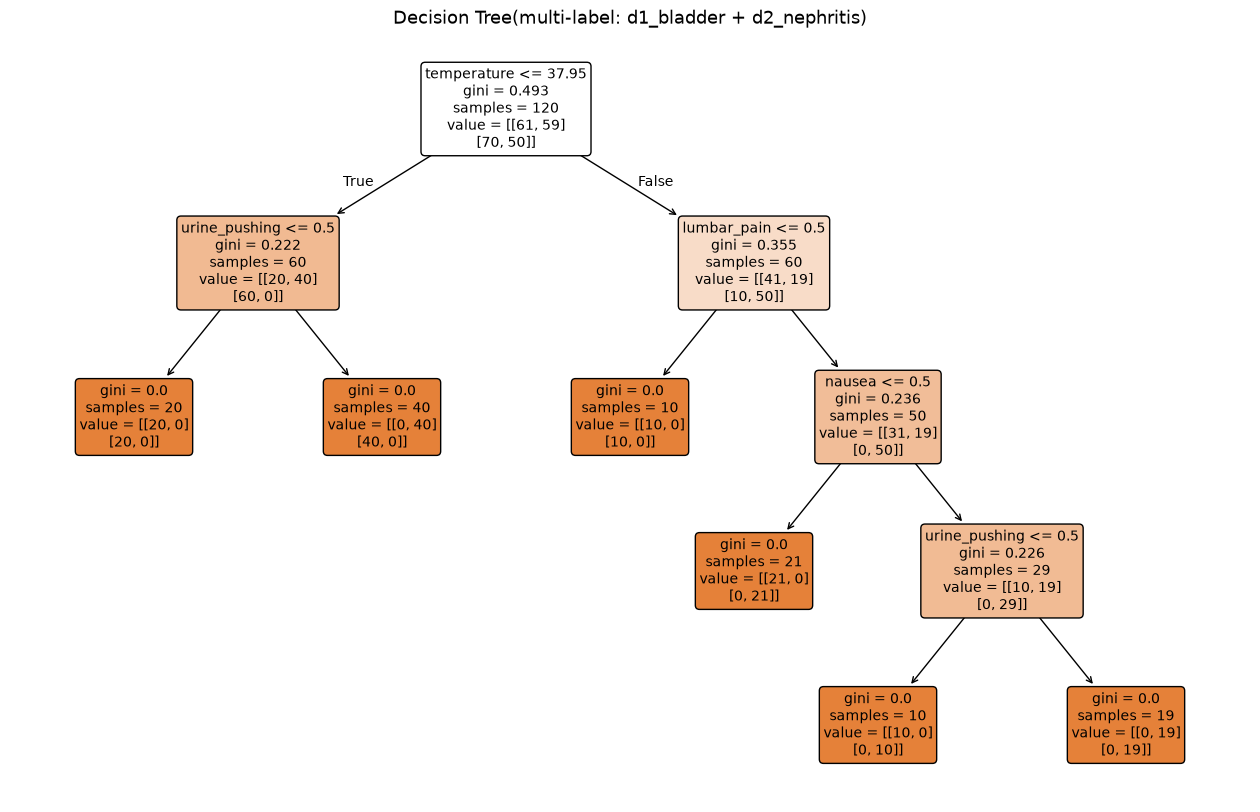

In [29]:
plt.figure(figsize=(16, 10))
plot_tree(tree, feature_names=ft_cols, class_names=['no', 'yes'], filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree(multi-label: d1_bladder + d2_nephritis)", fontsize=13)
plt.show()

### (c) Convert decision rules to IF-THEN rules

In [30]:
# fit one tree per label (binary relevance approach from the assignment footnote)
X_rules = df[ft_cols].values
y_d1 = df['d1_bladder'].values
y_d2 = df['d2_nephritis'].values

tree_d1 = DecisionTreeClassifier(criterion='gini', random_state=42)
tree_d1.fit(X_rules, y_d1)

tree_d2 = DecisionTreeClassifier(criterion='gini', random_state=42)
tree_d2.fit(X_rules, y_d2)

print("Tree for d1_bladder")
print(export_text(tree_d1, feature_names=ft_cols))
print(f"depth={tree_d1.get_depth()}, leaves={tree_d1.get_n_leaves()}")

print("\nTree for d2_nephritis")
print(export_text(tree_d2, feature_names=ft_cols))
print(f"depth={tree_d2.get_depth()}, leaves={tree_d2.get_n_leaves()}")

Tree for d1_bladder
|--- urine_pushing <= 0.50
|   |--- class: 0
|--- urine_pushing >  0.50
|   |--- micturition_pains <= 0.50
|   |   |--- burning_urethra <= 0.50
|   |   |   |--- class: 1
|   |   |--- burning_urethra >  0.50
|   |   |   |--- class: 0
|   |--- micturition_pains >  0.50
|   |   |--- class: 1

depth=3, leaves=4

Tree for d2_nephritis
|--- temperature <= 37.95
|   |--- class: 0
|--- temperature >  37.95
|   |--- lumbar_pain <= 0.50
|   |   |--- class: 0
|   |--- lumbar_pain >  0.50
|   |   |--- class: 1

depth=2, leaves=3


**IF-THEN rules we get from the tree:**

Each path from the root to a leaf gives one IF-THEN rule.

- **Rule 1:** IF `urine_pushing = no` AND `temperature <= 37.95` THEN d1_bladder = no AND d2_nephritis = no
- **Rule 2:** IF `urine_pushing = yes` AND `nausea = yes` THEN d1_bladder = yes AND d2_nephritis = yes

In [31]:
# my hard coded approach, this is not generic and should work only for this case
def predict_d1_bladder(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_urethra):
    if urine_pushing == 0:
        return "no"
    else:  # urine_pushing == 1
        if micturition_pains == 0:
            if burning_urethra == 0:
                return "yes"
            else:
                return "no"
        else:  # micturition_pains == 1
            return "yes"


def predict_d2_nephritis(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_urethra):

    if temperature <= 37.95:
        return "no"
    else:
        if lumbar_pain == 0:
            return "no"
        else:
            return "yes"


def predict_rules(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_urethra):

    d1 = predict_d1_bladder(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_urethra)
    d2 = predict_d2_nephritis(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_urethra)
    return (d1, d2)


# check for the whole dataset
all_match = True
for idx, row in df.iterrows():
    pred_d1, pred_d2 = predict_rules( row['temperature'], row['nausea'], row['lumbar_pain'], row['urine_pushing'], row['micturition_pains'], row['burning_urethra'])
    actual_d1 = 'yes' if row['d1_bladder'] == 1 else 'no'
    actual_d2 = 'yes' if row['d2_nephritis'] == 1 else 'no'
    if pred_d1 != actual_d1 or pred_d2 != actual_d2:
        all_match = False
        print(f"Mismatch at row {idx}: predicted ({pred_d1}, {pred_d2}), actual ({actual_d1}, {actual_d2})")

print(f"\nAll {len(df)} patients classified correctly: {all_match}")


All 120 patients classified correctly: True


In [32]:
# the generic approach (i worked on this with an AI assisted)
# generic function: converts any trained tree (including multi-output) to IF-THEN rules
def tree_to_rules(model, feature_names, label_names):
    tree_struct = model.tree_
    rules = []
    
    def visit(node, conditions):
        # a leaf has no children
        is_leaf = tree_struct.children_left[node] == tree_struct.children_right[node]
        
        if is_leaf:
            # look up predicted class for each label
            value = tree_struct.value[node]
            predictions = []
            for i, lbl in enumerate(label_names):
                predicted_class = int(np.argmax(value[i]))
                label_str = "yes" if predicted_class == 1 else "no"
                predictions.append(f"{lbl} = {label_str}")
            
            # format to the IF-THEN format
            if_part = " AND ".join(conditions) if conditions else "always"
            then_part = " AND ".join(predictions)
            n_samples = int(tree_struct.n_node_samples[node])
            rule = f"IF {if_part}  THEN  {then_part}  (n={n_samples})"
            rules.append(rule)
        else:
            # internal node: recurse into both branches ## ai assist
            feature = feature_names[tree_struct.feature[node]]
            threshold = tree_struct.threshold[node]
            
            left_cond = f"{feature} <= {threshold:.2f}"
            visit(tree_struct.children_left[node], conditions + [left_cond])
            
            right_cond = f"{feature} > {threshold:.2f}"
            visit(tree_struct.children_right[node], conditions + [right_cond])
    
    visit(0, [])
    return rules


# apply to the full dataset
rules = tree_to_rules(tree, ft_cols, label_cols)
print(f"Full tree has {len(rules)} IF-THEN rules:\n")
for i, r in enumerate(rules, 1):
    print(f"Rule {i}:")
    print(f"  {r}\n")

Full tree has 6 IF-THEN rules:

Rule 1:
  IF temperature <= 37.95 AND urine_pushing <= 0.50  THEN  d1_bladder = no AND d2_nephritis = no  (n=20)

Rule 2:
  IF temperature <= 37.95 AND urine_pushing > 0.50  THEN  d1_bladder = yes AND d2_nephritis = no  (n=40)

Rule 3:
  IF temperature > 37.95 AND lumbar_pain <= 0.50  THEN  d1_bladder = no AND d2_nephritis = no  (n=10)

Rule 4:
  IF temperature > 37.95 AND lumbar_pain > 0.50 AND nausea <= 0.50  THEN  d1_bladder = no AND d2_nephritis = yes  (n=21)

Rule 5:
  IF temperature > 37.95 AND lumbar_pain > 0.50 AND nausea > 0.50 AND urine_pushing <= 0.50  THEN  d1_bladder = no AND d2_nephritis = yes  (n=10)

Rule 6:
  IF temperature > 37.95 AND lumbar_pain > 0.50 AND nausea > 0.50 AND urine_pushing > 0.50  THEN  d1_bladder = yes AND d2_nephritis = yes  (n=19)



### (d) Cost-complexity pruning

Trying the 4 candidate alpha values
Best alpha: 0.000000
CV accuracy at best alpha: 0.9500


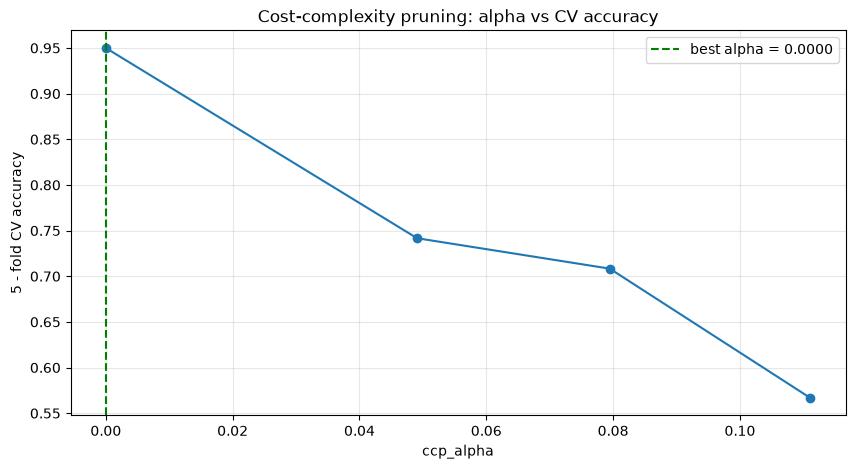

In [33]:
# sequence of alpha vals
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas[:-1]
print(f"Trying the {len(alphas)} candidate alpha values")

# 5 fold CV
scores = []
for a in alphas:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    score = cross_val_score(clf, X, y, cv=5).mean()
    scores.append(score)

# alpha with highest acc
best_idx = int(np.argmax(scores))
best_alpha = alphas[best_idx]
best_score = scores[best_idx]
print(f"Best alpha: {best_alpha:.6f}")
print(f"CV accuracy at best alpha: {best_score:.4f}")

# plots
plt.figure(figsize=(10, 5))
plt.plot(alphas, scores, marker='o')
plt.axvline(best_alpha, color='green', linestyle='--', label=f'best alpha = {best_alpha:.4f}')
plt.xlabel("ccp_alpha")
plt.ylabel("5 - fold CV accuracy")
plt.title("Cost-complexity pruning: alpha vs CV accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Original tree: depth = 4, leaves = 6
Pruned tree: depth = 4, leaves = 6


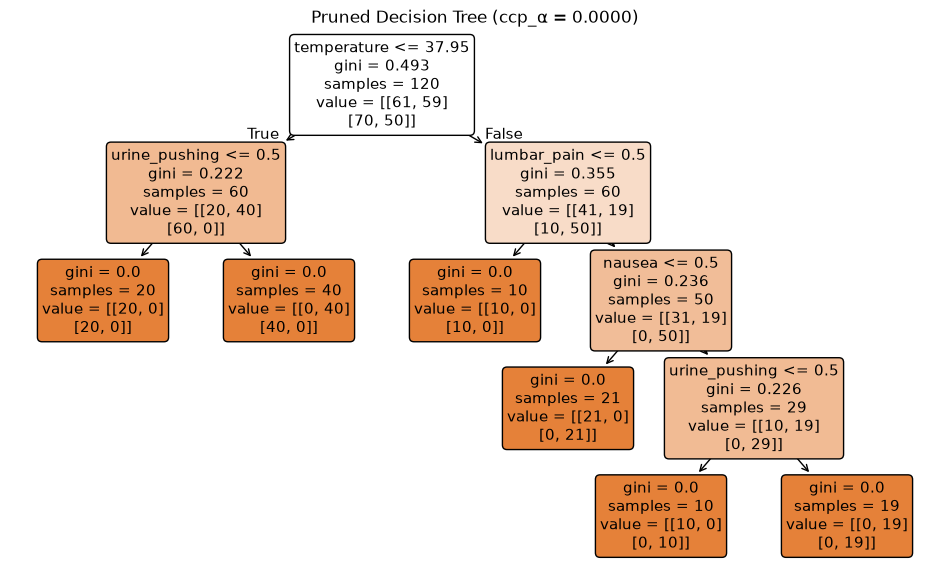


Pruned tree has 6 IF-THEN rules:

Rule 1:
  IF temperature <= 37.95 AND urine_pushing <= 0.50  THEN  d1_bladder = no AND d2_nephritis = no  (n=20)

Rule 2:
  IF temperature <= 37.95 AND urine_pushing > 0.50  THEN  d1_bladder = yes AND d2_nephritis = no  (n=40)

Rule 3:
  IF temperature > 37.95 AND lumbar_pain <= 0.50  THEN  d1_bladder = no AND d2_nephritis = no  (n=10)

Rule 4:
  IF temperature > 37.95 AND lumbar_pain > 0.50 AND nausea <= 0.50  THEN  d1_bladder = no AND d2_nephritis = yes  (n=21)

Rule 5:
  IF temperature > 37.95 AND lumbar_pain > 0.50 AND nausea > 0.50 AND urine_pushing <= 0.50  THEN  d1_bladder = no AND d2_nephritis = yes  (n=10)

Rule 6:
  IF temperature > 37.95 AND lumbar_pain > 0.50 AND nausea > 0.50 AND urine_pushing > 0.50  THEN  d1_bladder = yes AND d2_nephritis = yes  (n=19)



In [34]:
# fit tree with best alpha
pr_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
pr_tree.fit(X, y)

print(f"Original tree: depth = {tree.get_depth()}, leaves = {tree.get_n_leaves()}")
print(f"Pruned tree: depth = {pr_tree.get_depth()}, leaves = {pr_tree.get_n_leaves()}")

# plot the pruned tree
plt.figure(figsize=(12, 7))
plot_tree( pr_tree, feature_names=ft_cols, class_names=['no', 'yes'], filled=True, rounded=True, fontsize=11)
plt.title(f"Pruned Decision Tree (ccp_α = {best_alpha:.4f})")
plt.show()

# reuse the generic function to get IF-THEN rules
## ai assisted here for bugfixing
pruned_rules = tree_to_rules(pr_tree, ft_cols, label_cols)
print(f"\nPruned tree has {len(pruned_rules)} IF-THEN rules:\n")
for i, r in enumerate(pruned_rules, 1):
    print(f"Rule {i}:")
    print(f"  {r}\n")

**Observations for (1d):**

- The original tree already has only 6 leaves and depth 4. Cost-complexity pruning picked **best alpha was 0.0000**, meaning no splits were removed.
- The 6 IF-THEN rules are directly readable as a medical decision guide:
    - **Rule 1 (n=20):** Low temperature and no urine pushing, patient is healthy on both diagnoses.
    - **Rule 2 (n=40):** Low temperature with urine pushing indicates bladder inflammation only, no nephritis.
    - **Rule 3 (n=10):** High temperature but no lumbar pain, patient is healthy on both diagnoses.
    - **Rules 4 and 5 (n=21 and n=10):** High temperature with lumbar pain indicates nephritis, bladder depends on the other symptoms.
    - **Rule 6 (n=19):** The full symptom combination (fever + lumbar pain + nausea + urine pushing) indicates both diagnoses together.

## Problem 2 - The l and Boosting for Regression

### (a) Dataset

- 1,994 instances, 128 columns (5 non-predictive + 122 predictive features + 1 target)
- Target variable: `ViolentCrimesPerPop` (last column)
- Train set: first 1,495 rows. Test set: remaining 499 rows.

Stored at `../data/communities.data`.

In [35]:
# load file
p2_path = "../data/communities.data"
p2_data = pd.read_csv(p2_path, header=None, na_values='?')

print("Shape:", p2_data.shape)   # should be (1994, 128)
print("Missing values total:", p2_data.isna().sum().sum())
print("Columns with any missing (first 15):")
missing_counts = p2_data.isna().sum()
print(missing_counts[missing_counts > 0].head(15))

Shape: (1994, 128)
Missing values total: 39202
Columns with any missing (first 15):
1      1174
2      1177
30        1
101    1675
102    1675
103    1675
104    1675
105    1675
106    1675
107    1675
108    1675
109    1675
110    1675
111    1675
112    1675
dtype: int64


### (b) Drop non-predictive features and impute missing values

In [36]:
# drop the 5 non-predictive columns and separate features from target
X_all = p2_data.iloc[:, 5:127].copy()
y_all = p2_data.iloc[:, 127].copy()

print("Feature matrix shape:", X_all.shape)
print("Target shape:", y_all.shape)
print(f"Target range: [{y_all.min():.4f}, {y_all.max():.4f}]")
print(f"Missing values in features before imputation: {X_all.isna().sum().sum()}")

# test train split
X_train_raw = X_all.iloc[:1495].reset_index(drop=True)
X_test_raw = X_all.iloc[1495:].reset_index(drop=True)
y_train = y_all.iloc[:1495].reset_index(drop=True)
y_test = y_all.iloc[1495:].reset_index(drop=True)

print(f"\nTrain shape: {X_train_raw.shape} / {y_train.shape}")
print(f"Test shape:  {X_test_raw.shape} / {y_test.shape}")

# impute with mean
imputer = SimpleImputer(strategy='mean')
X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw), # fir train only
    columns=X_train_raw.columns,
)
X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
)

print(f"\nMissing values after imputation: train={X_train.isna().sum().sum()}, test={X_test.isna().sum().sum()}")

Feature matrix shape: (1994, 122)
Target shape: (1994,)
Target range: [0.0000, 1.0000]
Missing values in features before imputation: 36851

Train shape: (1495, 122) / (1495,)
Test shape:  (499, 122) / (499,)

Missing values after imputation: train=0, test=0


### (c) Correlation matrix of features

With 122 features we see the full correlation matrix is 122×122. We can plot it as a heatmap

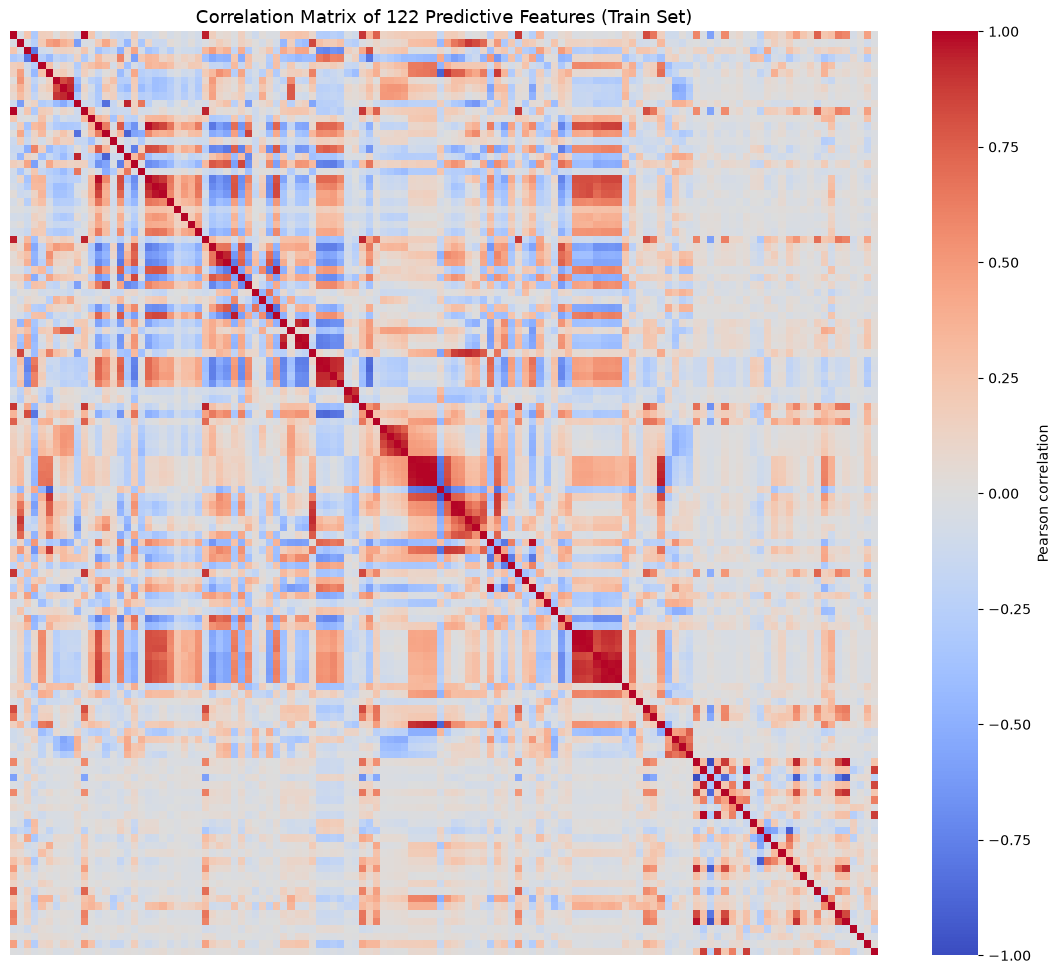

Pairs with |correlation| > 0.8: 152
Pairs with |correlation| > 0.9: 61


In [37]:
# correlation matrix
corr = X_train.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False, cbar_kws={'label': 'Pearson correlation'})
plt.title("Correlation Matrix of 122 Predictive Features (Train Set)", fontsize=13) ## ai assist
plt.show()

upper_tri = np.triu(np.abs(corr.values), k=1) 
high_corr_pairs = (upper_tri > 0.8).sum()
print(f"Pairs with |correlation| > 0.8: {high_corr_pairs}")
print(f"Pairs with |correlation| > 0.9: {(upper_tri > 0.9).sum()}")

**Observation:** The heatmap shows mulitple clusters of highly correlated features. Shows multicollineartiy.

### (d) Coefficient of Variation (CV)

For each feature, we compute the Coefficient of Variation: CV = s / m, where s is sample standard deviation and m is sample mean

In [38]:
# compute CV
means = X_train.mean()
stds = X_train.std()

## llm assisted bugfix here
cv_values = (stds / means.abs()).replace([np.inf, -np.inf], np.nan)

# rank features by |CV| descending
cv_df = pd.DataFrame({'feature_idx': X_train.columns, 'mean': means.values, 'std': stds.values, 'CV': cv_values.values, 'abs_CV': cv_values.abs().values,}).sort_values('abs_CV', ascending=False).reset_index(drop=True)

print("Top 15 features by |CV|:")
print(cv_df.head(15))
print(f"\nTotal features: {len(cv_df)}")

Top 15 features by |CV|:
    feature_idx      mean       std        CV    abs_CV
0            95  0.022983  0.098665  4.292923  4.292923
1            94  0.029599  0.102736  3.470952  3.470952
2            54  0.037204  0.113806  3.058964  3.058964
3            56  0.030595  0.089541  2.926635  2.926635
4           125  0.093304  0.238201  2.552946  2.552946
5            32  0.056849  0.133167  2.342443  2.342443
6             5  0.058167  0.130359  2.241105  2.241105
7            15  0.064649  0.131784  2.038461  2.038461
8            76  0.076475  0.150538  1.968467  1.968467
9           118  0.064107  0.105482  1.645408  1.645408
10           10  0.144963  0.233694  1.612091  1.612091
11           66  0.151880  0.221231  1.456618  1.456618
12            7  0.179839  0.256970  1.428885  1.428885
13          120  0.165197  0.230799  1.397110  1.397110
14            9  0.153712  0.208910  1.359100  1.359100

Total features: 122


### (e) Pick root(128) approx. = 11 features with highest CV, scatter and box plots

We select the 11 features with the largest CV values and inspect them visually against the target.

Selected 11 features with highest CV: [95, 94, 54, 56, 125, 32, 5, 15, 76, 118, 10]


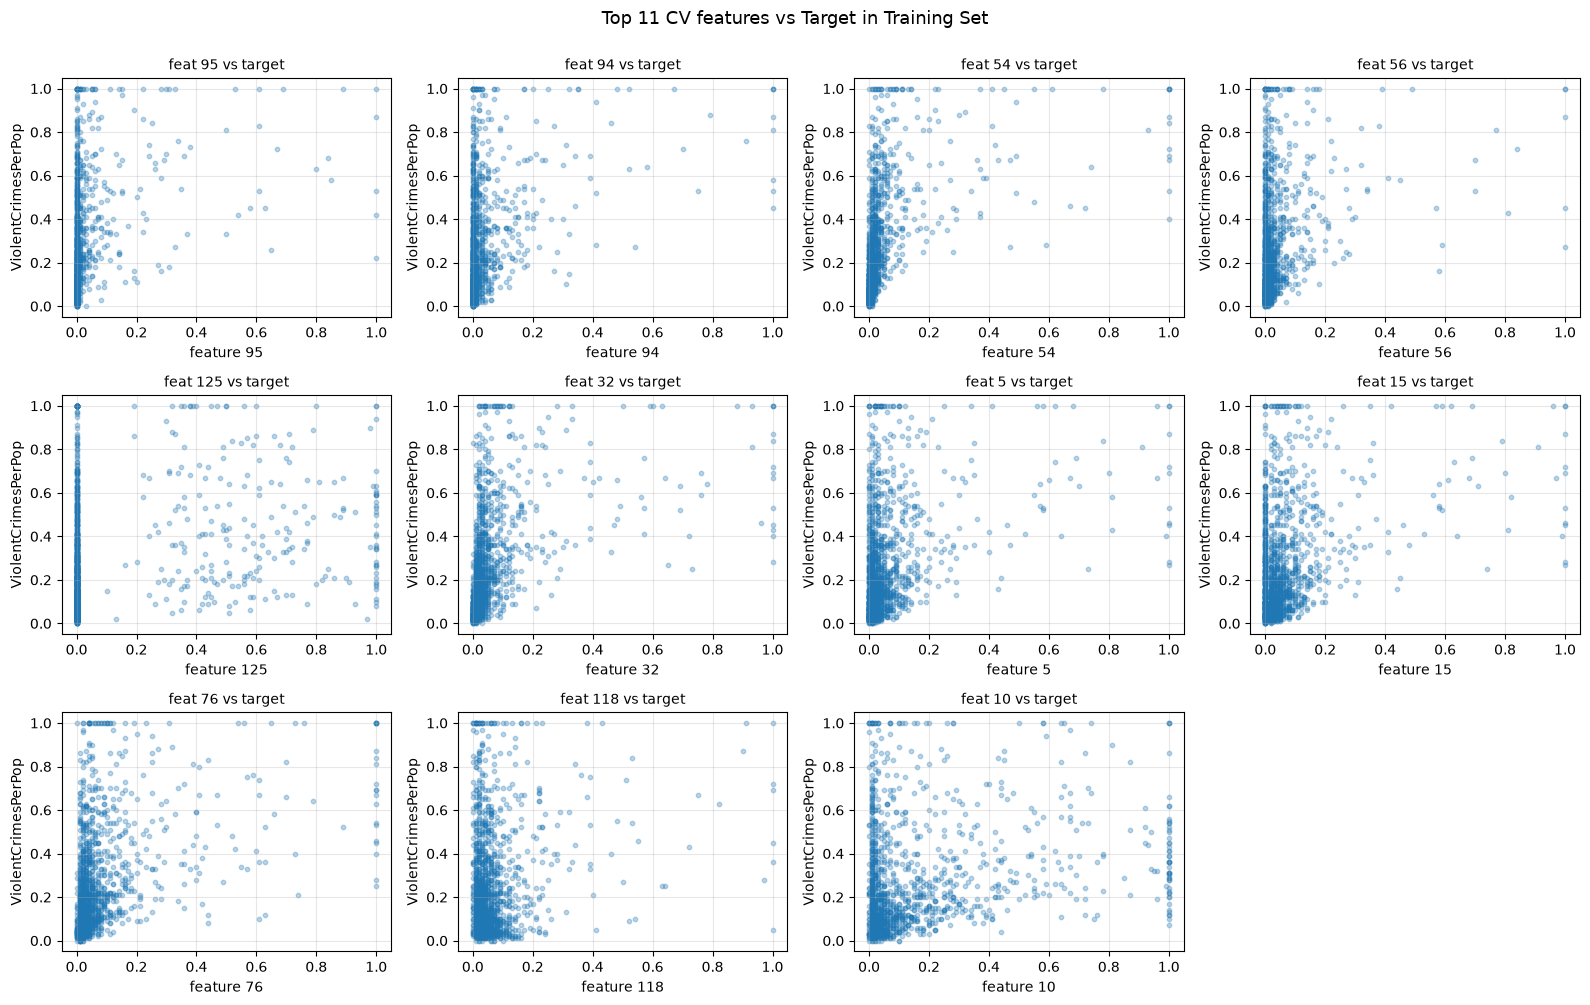

In [39]:
n_select = 11
top_features = cv_df['feature_idx'].head(n_select).tolist()
print(f"Selected {n_select} features with highest CV: {top_features}")

# scatter plo
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, f in enumerate(top_features):
    axes[i].scatter(X_train[f], y_train, alpha=0.3, s=10) ## llm assisted bugfixing here
    axes[i].set_xlabel(f'feature {f}')
    axes[i].set_ylabel('ViolentCrimesPerPop')
    axes[i].set_title(f'feat {f} vs target', fontsize=10)
    axes[i].grid(True, alpha=0.3)

## llm assisted bugfix i missed this line to hide last
axes[11].axis('off')

plt.suptitle(f"Top {n_select} CV features vs Target in Training Set", fontsize=13, y=1.00)
plt.tight_layout()
plt.show()

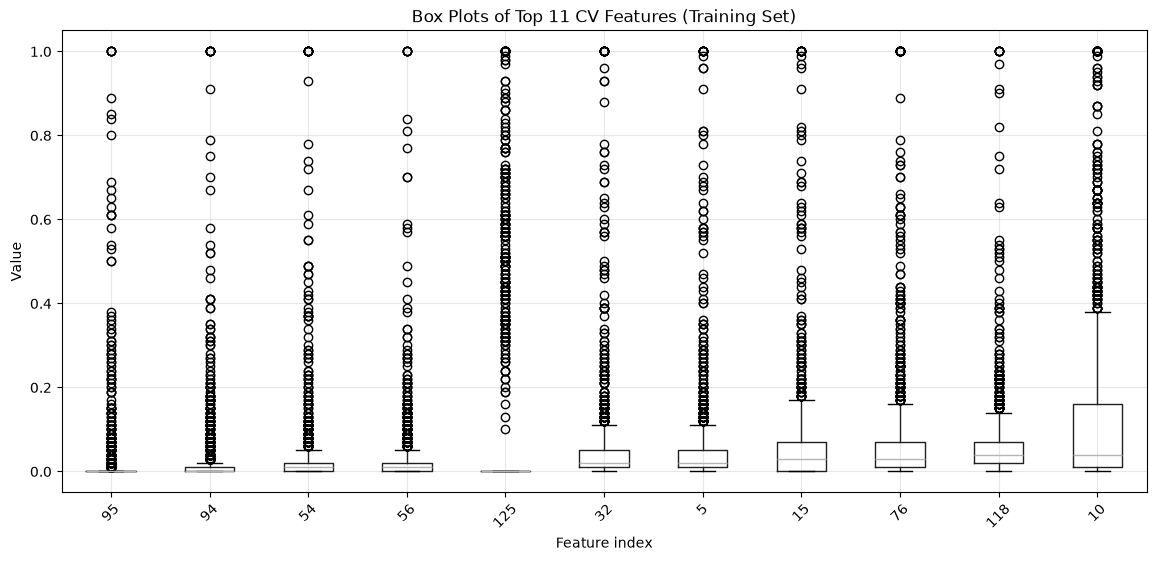

In [40]:
# boxplot 

plt.figure(figsize=(14, 6))
X_train[top_features].boxplot()
plt.title(f"Box Plots of Top {n_select} CV Features (Training Set)")
plt.xlabel("Feature index")
plt.ylabel("Value")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

**Observations (2 e):**

- The 11 selected features have the widest relative variability (highest CV). Many of them show heavy right-skewed distributions in the box plots with long tails above the IQR.
- **Can we draw conclusions about significance just from the scatter plots?** No. CV only ranks features by their own variability and not exactl by how well they predict the target.
- The right thing here is to fit regression models like OLS, Ridge, l etc.

### (f) Linear regression (OLS) with test error

In [41]:
# plain OLS linear regression
ols = LinearRegression()
ols.fit(X_train, y_train)

y_pred_ols = ols.predict(X_test)
mse_ols = mean_squared_error(y_test, y_pred_ols)
print(f"OLS Test MSE: {mse_ols:.6f}")
print(f"OLS Test RMSE: {np.sqrt(mse_ols):.6f}")

OLS Test MSE: 0.018142
OLS Test RMSE: 0.134692


### (g) Ridge regression with lambda chosen by cross-validation

In [42]:
# ridge with internal CV
alphas_ridge = np.logspace(-3, 3, 100)
ridge = RidgeCV(alphas=alphas_ridge, cv=5)
ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print(f"Ridge: best alpha (= lambda) = {ridge.alpha_:.4f}")
print(f"Ridge Test MSE: {mse_ridge:.6f}")
print(f"Ridge Test RMSE: {np.sqrt(mse_ridge):.6f}")

Ridge: best alpha (= lambda) = 2.1544
Ridge Test MSE: 0.017610
Ridge Test RMSE: 0.132703


### (h) Lasso regression (raw + standardized features)

In [45]:
# lasso on raw data
alpha_l = np.logspace(-5, 1, 100)

l_raw = LassoCV(alphas=alpha_l, cv=5, max_iter=20000, random_state=42)
l_raw.fit(X_train, y_train)

y_pred_l_raw = l_raw.predict(X_test)
mse_l_raw = mean_squared_error(y_test, y_pred_l_raw)

## llm assisted bugfix
selected_raw = np.where(l_raw.coef_ != 0)[0]
print(f"l (raw): best alpha = {l_raw.alpha_:.6f}")
print(f"l (raw) Test MSE: {mse_l_raw:.6f}")
print(f"l (raw) selected {len(selected_raw)} features out of {X_train.shape[1]}")
print(f"Selected feature indices: {selected_raw.tolist()}")

l (raw): best alpha = 0.000123
l (raw) Test MSE: 0.017740
l (raw) selected 75 features out of 122
Selected feature indices: [2, 4, 6, 7, 11, 13, 14, 15, 16, 17, 18, 21, 22, 23, 24, 25, 26, 28, 29, 33, 34, 36, 38, 39, 40, 44, 45, 46, 48, 49, 50, 51, 52, 55, 59, 61, 63, 64, 67, 68, 69, 70, 71, 72, 74, 75, 76, 77, 78, 79, 82, 85, 86, 87, 88, 89, 90, 91, 92, 94, 99, 100, 102, 104, 106, 108, 111, 112, 113, 114, 115, 118, 119, 120, 121]


In [46]:
# lasso on standardized data
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std  = scaler.transform(X_test)

l_std = LassoCV(alphas=alpha_l, cv=5, max_iter=20000, random_state=42) 
l_std.fit(X_train_std, y_train)

y_pred_lasso_std = l_std.predict(X_test_std)
mse_lasso_std = mean_squared_error(y_test, y_pred_lasso_std)

selected_std = np.where(l_std.coef_ != 0)[0]
print(f"LASSO (standardized): best alpha = {l_std.alpha_:.6f}")
print(f"LASSO (standardized) Test MSE: {mse_lasso_std:.6f}")
print(f"LASSO (standardized) selected {len(selected_std)} features out of {X_train_std.shape[1]}")
print(f"Selected feature indices: {selected_std.tolist()}")

LASSO (standardized): best alpha = 0.000756
LASSO (standardized) Test MSE: 0.017807
LASSO (standardized) selected 73 features out of 122
Selected feature indices: [2, 4, 6, 7, 11, 13, 14, 15, 16, 17, 18, 21, 22, 23, 24, 25, 26, 28, 29, 33, 34, 38, 39, 40, 44, 45, 46, 48, 49, 50, 51, 53, 55, 59, 61, 63, 64, 67, 68, 69, 71, 72, 74, 75, 76, 77, 78, 82, 85, 86, 87, 88, 89, 90, 91, 94, 99, 100, 102, 104, 105, 106, 107, 108, 110, 111, 112, 113, 114, 115, 116, 118, 119]


In [47]:
summary = pd.DataFrame({
    'Model': ['OLS', 'Ridge (CV)', 'LASSO (raw)', 'LASSO (standardized)'],
    'Best alpha': ['n/a', f'{ridge.alpha_:.4f}', f'{l_raw.alpha_:.6f}', f'{l_std.alpha_:.6f}'],
    'Test MSE': [round(mse_ols, 6), round(mse_ridge, 6), round(mse_l_raw, 6), round(mse_lasso_std, 6)], ## llm assisted bugfix on this line
    'Test RMSE': [round(np.sqrt(mse_ols), 6), round(np.sqrt(mse_ridge), 6), round(np.sqrt(mse_l_raw), 6), round(np.sqrt(mse_lasso_std), 6)],
    'Features used': [122, 122, len(selected_raw), len(selected_std)],
})
summary

,Model,Best alpha,Test MSE,Test RMSE,Features used
0,OLS,n/a,0.018142,0.134692,122
1,Ridge (CV),2.1544,0.017610,0.132703,122
2,LASSO (raw),0.000123,0.017740,0.133192,75
3,LASSO (standardized),0.000756,0.017807,0.133444,73


### (i) Principal Component Regression (PCR)

Best M = 95, CV MSE at best M = 0.019350


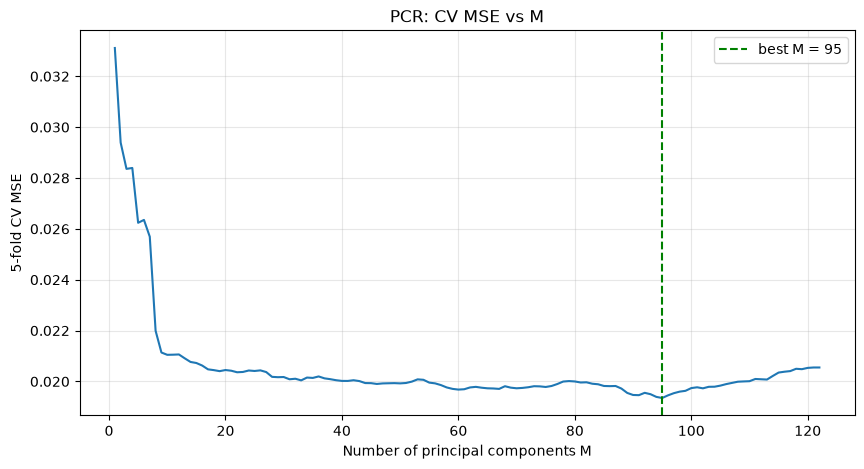

In [48]:
# PCR setup as below standardize -> PCA(M) -> OLS

M_values = list(range(1, 123))
cv_mse_pcr = []

for M in M_values:
    pcr_pipe = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=M, random_state=42)), ('ols', LinearRegression())])
    # 5-fold CV
    scores = cross_val_score(pcr_pipe, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    cv_mse_pcr.append(-scores.mean())

# pick M
best_M = M_values[int(np.argmin(cv_mse_pcr))]
print(f"Best M = {best_M}, CV MSE at best M = {min(cv_mse_pcr):.6f}")

# plot CV MSE vs M
plt.figure(figsize=(10, 5))
plt.plot(M_values, cv_mse_pcr)
plt.axvline(best_M, color='green', linestyle='--', label=f'best M = {best_M}')
plt.xlabel("Number of principal components M")
plt.ylabel("5-fold CV MSE")
plt.title("PCR: CV MSE vs M")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [49]:
# refit PCR for best M
pcr_final = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=best_M, random_state=42)), ('ols', LinearRegression())])
pcr_final.fit(X_train, y_train)

y_pred_pcr = pcr_final.predict(X_test)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)
print(f"PCR (M={best_M}) Test MSE: {mse_pcr:.6f}")
print(f"PCR (M={best_M}) Test RMSE: {np.sqrt(mse_pcr):.6f}")

PCR (M=95) Test MSE: 0.018393
PCR (M=95) Test RMSE: 0.135621


### (j) L1-penalized Gradient Boosting Tree (XGBoost)

In [50]:
# L1-penalized GB
alphas_xgb = [0.0, 0.001, 0.01, 0.1, 1.0, 10.0]

xgb_model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=4, objective='reg:squarederror', random_state=42, n_jobs=-1) ## had to look this up online

grid = GridSearchCV(xgb_model, param_grid={'reg_alpha': alphas_xgb}, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(X_train, y_train)

best_alpha_xgb = grid.best_params_['reg_alpha']
print(f"Best alpha (reg_alpha): {best_alpha_xgb}")
print(f"Best CV MSE: {-grid.best_score_:.6f}")

# evaluatnig on test
y_pred_xgb = grid.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
print(f"XGBoost Test MSE: {mse_xgb:.6f}")
print(f"XGBoost Test RMSE: {np.sqrt(mse_xgb):.6f}")

Best alpha (reg_alpha): 1.0
Best CV MSE: 0.020470
XGBoost Test MSE: 0.016327
XGBoost Test RMSE: 0.127778


In [ ]:
# full comparison table (built with an llm assist, I had a long messy data frame but copilot sort of corrected and mde it concise)
final_summ = pd.DataFrame({
    'Model': ['OLS', 'Ridge (CV)', 'LASSO (raw)', 'LASSO (standardized)', f'PCR (M={best_M})', f'XGBoost (alpha={best_alpha_xgb})'],
    'Test MSE': [round(mse_ols, 6), round(mse_ridge, 6), round(mse_l_raw, 6), round(mse_lasso_std, 6), round(mse_pcr, 6), round(mse_xgb, 6)],
    'Test RMSE': [round(np.sqrt(mse_ols), 6), round(np.sqrt(mse_ridge), 6), round(np.sqrt(mse_l_raw), 6), round(np.sqrt(mse_lasso_std), 6), round(np.sqrt(mse_pcr), 6), round(np.sqrt(mse_xgb), 6)],
})
final_summ.sort_values('Test MSE').reset_index(drop=True)

,Model,Test MSE,Test RMSE
0,XGBoost (alpha=1.0),0.016327,0.127778
1,Ridge (CV),0.017610,0.132703
2,LASSO (raw),0.017740,0.133192
3,LASSO (standardized),0.017807,0.133444
4,OLS,0.018142,0.134692
5,PCR (M=95),0.018393,0.135621


**Final Observations:**

- **Best-performing model: XGBoost (alpha = 1.0) with Test MSE = 0.016327**
- **Ridge (CV) edges out LASSO** (0.0176 vs 0.0177). Bothhave outperformed plain OLS confirming that regularization helps on this multicollinear dataset.
- **LASSO (raw) ≈ LASSO (standardized)** 
- **PCR (M = 95) actually performed worst (0.0184)**